In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.style.use("paper_style.mplstyle")
from paper_palette import (
    MORPHO_COLOR, AAVE_COLOR,
    WHALE_COLOR, WHALE_COLOR_LIGHT,
    RETAILER_COLOR, RETAILER_COLOR_LIGHT,
    TOKEN_COLORS,
)


In [2]:
morpho_files = {
    "sUSDe": "../from_dune/borrowers/morpho_borrowers_susde.csv",
    "sUSDS": "../from_dune/borrowers/morpho_borrowers_susds.csv",
    "syrupUSDC": "../from_dune/borrowers/morpho_borrowers_syrup.csv",
}

aave_files = {
    "sUSDe": "../from_dune/borrowers/aave_borrowers_susde.csv",
}
DUST_THRESHOLD_USD = 50_000

morpho_dfs = {name: pd.read_csv(path) for name, path in morpho_files.items()}
aave_dfs = {name: pd.read_csv(path) for name, path in aave_files.items()}

In [3]:
def morpho_market_summary(df):
    summary = (
        df.groupby("market_label")
        .agg(
            borrowers=("address", "nunique"),
            total_collateral_usd=("collateral_value_usd", "sum"),
            total_borrowed=("borrowed_value", "sum"),
        )
        .reset_index()
        .sort_values("total_collateral_usd", ascending=False)
    )
    summary = summary[summary["total_collateral_usd"] >= DUST_THRESHOLD_USD]
    return summary

morpho_summaries = {name: morpho_market_summary(df) for name, df in morpho_dfs.items()}

for name, summary in morpho_summaries.items():
    print(f"--- Morpho, {name} ---")
    print(summary)
    print()

--- Morpho, sUSDe ---
  market_label  borrowers  total_collateral_usd  total_borrowed
2        PYUSD         18          4.138352e+07    3.614184e+07
5        USDtb         27          1.130871e+07    9.448588e+06
1          DAI         73          2.464054e+06    1.874697e+06
6        msUSD         20          5.700565e+05    4.899118e+05
4         USDT         26          2.060375e+05    1.852390e+05
3         USDC          7          5.542849e+04    8.439856e+03

--- Morpho, sUSDS ---
  market_label  borrowers  total_collateral_usd  total_borrowed
3         USDT         78          6.503892e+07    5.872122e+07
0         AUSD         11          4.280991e+06    3.792390e+06

--- Morpho, syrupUSDC ---
  market_label  borrowers  total_collateral_usd  total_borrowed
1        PYUSD         22          7.834305e+07    6.716401e+07
2        RLUSD         24          3.715549e+07    3.052333e+07
0         AUSD         20          2.368718e+07    2.032093e+07
3         USDC         16       

In [4]:
def aave_market_summary(df):
    summary = (
        df.groupby("debt_symbol")
        .agg(
            borrowers=("address", "nunique"),
            total_collateral_usd=("collateral_value_usd", "sum"),
            total_borrowed=("borrowed_value", "sum"),
        )
        .reset_index()
        .sort_values("total_collateral_usd", ascending=False)
    )
    summary = summary[summary["total_collateral_usd"] >= DUST_THRESHOLD_USD]
    return summary

aave_summaries = {name: aave_market_summary(df) for name, df in aave_dfs.items()}

for name, summary in aave_summaries.items():
    print(f"--- Aave, {name} ---")
    print(summary)
    print()

--- Aave, sUSDe ---
   debt_symbol  borrowers  total_collateral_usd  total_borrowed
23        USDT        680          9.865470e+08    1.216489e+08
20        USDC        567          7.759738e+08    1.715859e+08
24        USDe        250          5.397918e+08    1.599680e+08
27        WETH        133          2.105951e+08    4.667478e+02
9          GHO        158          1.776061e+08    6.167490e+06
22        USDS         51          1.767218e+08    7.202649e+04
28       cbBTC         21          1.355158e+08    1.103061e+00
25       USDtb         41          1.154805e+08    5.932645e+06
35       weETH          7          4.709123e+07    0.000000e+00
3          DAI         32          4.459448e+07    2.375999e+01
36      wstETH         41          4.411013e+07    6.050000e-03
2          CRV          4          3.031516e+07    0.000000e+00
33        rETH          1          3.021478e+07    0.000000e+00
32     no debt        122          2.193744e+07    0.000000e+00
26        WBTC      

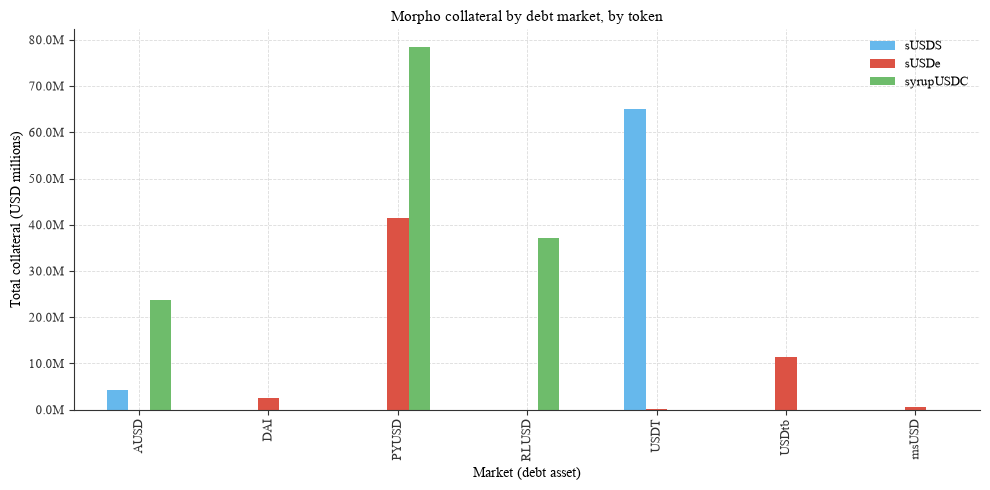

In [5]:
morpho_combined = pd.concat(
    [summary.assign(token=name) for name, summary in morpho_summaries.items()]
)

morpho_pivot = morpho_combined.pivot(index="market_label", columns="token", values="total_collateral_usd").fillna(0)
morpho_pivot = morpho_pivot.drop(index="USDC", errors="ignore")

fig, ax = plt.subplots(figsize=(10, 5))
morpho_pivot = morpho_pivot[[c for c in TOKEN_COLORS if c in morpho_pivot.columns]]
morpho_pivot.plot(kind="bar", ax=ax, color=[TOKEN_COLORS[c] for c in morpho_pivot.columns])
ax.set_title("Morpho collateral by debt market, by token")
ax.set_ylabel("Total collateral (USD millions)")
ax.set_xlabel("Market (debt asset)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1_000_000:.1f}M"))
ax.legend(title="")
plt.tight_layout()
plt.savefig("../output/morpho_collateral_by_market_combined.png", dpi=300, bbox_inches="tight")
plt.show()

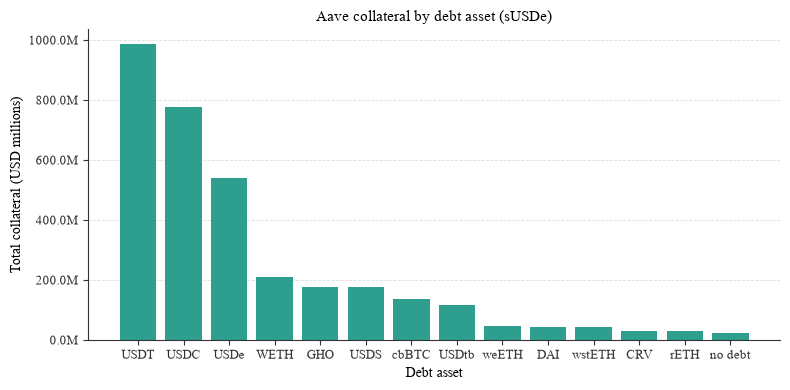

In [6]:
DUST_THRESHOLD_USD = 20_000_000

for name, summary in aave_summaries.items():
    plot_summary = summary[summary["total_collateral_usd"] > DUST_THRESHOLD_USD]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(plot_summary["debt_symbol"], plot_summary["total_collateral_usd"], color=AAVE_COLOR)
    ax.set_title(f"Aave collateral by debt asset ({name})")
    ax.set_ylabel("Total collateral (USD millions)")
    ax.set_xlabel("Debt asset")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1_000_000:.1f}M"))
    plt.tight_layout()
    plt.savefig(f"../output/aave_collateral_by_market_{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [7]:
per_address = aave_dfs["sUSDe"].groupby("address").agg(
    collateral_value_usd=("collateral_value_usd", "first"),
    has_active_debt=("borrowed_value", lambda x: (x > 0).any()),
).reset_index()

per_address["archetype"] = per_address["has_active_debt"].map({True: "stablecoin_borrow", False: "collateral_only"})

print(per_address["archetype"].value_counts())

archetype
collateral_only      799
stablecoin_borrow    361
Name: count, dtype: int64


In [8]:
STABLECOINS = {"USDT", "USDC", "USDe", "GHO", "EURC", "RLUSD", "USDtb", "PYUSD", "DAI", "USDS", "AUSD"}

df = aave_dfs["sUSDe"].copy()
df["is_stable"] = df["debt_symbol"].isin(STABLECOINS)
df["active_stable_row"] = (df["borrowed_value"] > 0) & df["is_stable"]
df["active_nonstable_row"] = (df["borrowed_value"] > 0) & (~df["is_stable"])

per_address = df.groupby("address").agg(
    has_active_stable=("active_stable_row", "any"),
    has_active_nonstable=("active_nonstable_row", "any"),
).reset_index()

def classify(row):
    if row["has_active_stable"]:
        return "stablecoin_borrow"
    elif row["has_active_nonstable"]:
        return "non_stable_borrow"
    else:
        return "collateral_only"

per_address["archetype"] = per_address.apply(classify, axis=1)
print(per_address["archetype"].value_counts())

archetype
collateral_only      799
stablecoin_borrow    347
non_stable_borrow     14
Name: count, dtype: int64


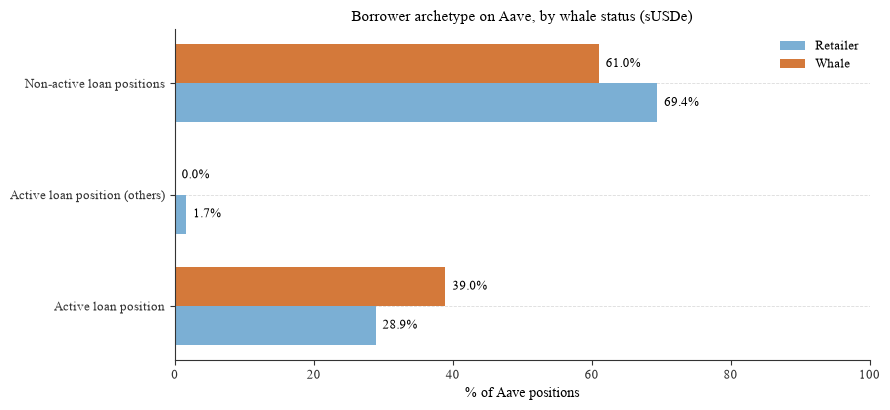

In [9]:
import numpy as np

STABLECOINS = {"USDT", "USDC", "USDe", "USDS", "GHO", "RLUSD", "USDtb", "PYUSD", "DAI", "USDS", "AUSD"}

aave_whales = pd.read_csv("aave_whales.csv")

def classify_address_archetype(row):
    if row["has_active_stable"]:
        return "stablecoin_borrow"
    elif row["has_active_nonstable"]:
        return "non_stable_borrow"
    else:
        return "collateral_only"

def aave_archetype_by_whale(df, token):
    df = df.copy()
    df["is_stable"] = df["debt_symbol"].isin(STABLECOINS)
    df["active_stable_row"] = (df["borrowed_value"] > 0) & df["is_stable"]
    df["active_nonstable_row"] = (df["borrowed_value"] > 0) & (~df["is_stable"])

    whale_addresses = set(aave_whales.loc[aave_whales["asset"] == token, "wallet"])

    per_address = df.groupby("address").agg(
        has_active_stable=("active_stable_row", "any"),
        has_active_nonstable=("active_nonstable_row", "any"),
    ).reset_index()

    per_address["archetype"] = per_address.apply(classify_address_archetype, axis=1)
    per_address["is_whale"] = per_address["address"].isin(whale_addresses)

    total_nonwhale = (~per_address["is_whale"]).sum()
    total_whale = per_address["is_whale"].sum()

    archetypes = ["collateral_only", "non_stable_borrow", "stablecoin_borrow"]
    nonwhale_pct = [100 * ((per_address["is_whale"] == False) & (per_address["archetype"] == a)).sum() / total_nonwhale for a in archetypes]
    whale_pct = [100 * ((per_address["is_whale"] == True) & (per_address["archetype"] == a)).sum() / total_whale for a in archetypes]

    return archetypes, nonwhale_pct, whale_pct

for name, df in aave_dfs.items():
    archetypes, nonwhale, whale = aave_archetype_by_whale(df, name)

    y = np.arange(len(archetypes))
    h = 0.35

    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.barh(y + h/2, nonwhale, height=h, color=RETAILER_COLOR, label="Retailer")
    ax.barh(y - h/2, whale, height=h, color=WHALE_COLOR, label="Whale")
    ax.set_yticks(y)
    ax.set_yticklabels(["Non-active loan positions", "Active loan position (others)", "Active loan position"])
    ax.set_xlabel("% of Aave positions")
    ax.set_title(f"Borrower archetype on Aave, by whale status ({name})")
    ax.invert_yaxis()
    for i, (nv, wv) in enumerate(zip(nonwhale, whale)):
        ax.text(nv + 1, i + h/2, f"{nv:.1f}%", va="center", fontsize=9)
        ax.text(wv + 1, i - h/2, f"{wv:.1f}%", va="center", fontsize=9)
    ax.set_xlim(0, 100)
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.savefig(f"../output/aave_looping_archetype_mix_{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [10]:
STABLECOINS = {"USDT", "USDC", "USDe", "USDS", "GHO", "RLUSD", "USDtb", "PYUSD", "DAI", "AUSD"}

df = aave_dfs["sUSDe"].copy()
df["is_stable"] = df["debt_symbol"].isin(STABLECOINS)
df["active_stable_row"] = (df["borrowed_value"] > 0) & df["is_stable"]
df["active_nonstable_row"] = (df["borrowed_value"] > 0) & (~df["is_stable"])

per_address = df.groupby("address").agg(
    collateral_value_usd=("collateral_value_usd", "first"),
    has_active_stable=("active_stable_row", "any"),
    has_active_nonstable=("active_nonstable_row", "any"),
).reset_index()

def classify_address_archetype(row):
    if row["has_active_stable"]:
        return "stablecoin_borrow"
    elif row["has_active_nonstable"]:
        return "non_stable_borrow"
    else:
        return "collateral_only"

per_address["archetype"] = per_address.apply(classify_address_archetype, axis=1)

TOP_N = 15
top_supply_only = (
    per_address[per_address["archetype"] == "collateral_only"]
    .sort_values("collateral_value_usd", ascending=False)
    .head(TOP_N)
    .reset_index(drop=True)
)

print(top_supply_only[["address", "collateral_value_usd"]])

                                       address  collateral_value_usd
0   0xa9ed0db00e5c29e7e18a55db159ea33fb5fea60a          1.208721e+08
1   0xb3f0c00b0fc69baab5f9318b61a7b67f412a4b8b          1.984000e+07
2   0x5c2c1aa8cebdeb2225e93481f93469ac8e1d210f          1.861121e+07
3   0xaf9b98d2acde5f13eaeaeb0101273cdfa86dcc95          1.487110e+07
4   0xdbc652411605f8bb8969136923aa039c79989482          1.483558e+07
5   0xaa32471239b3a1bca2aecbc8cea2b1be766ae009          1.414178e+07
6   0xcd0673721a489b1cea0e2580fa304bcb6cca3186          1.257949e+07
7   0x2a7db8653ed56dd8ca5d413997a1fab66aa326b0          1.253794e+07
8   0xce344e5ad5bab578601cbf8ad103506588d38455          1.202326e+07
9   0x0daf132c5554fd7d5eb422585426af557d8847e0          9.717892e+06
10  0x2a52bf79e63296c08e2853b194ab43b92972897a          9.267529e+06
11  0x04caf56067fed0cb0959428fa641edb681fcdf43          8.070715e+06
12  0x06f5c1e53f803c3554c4a044dec4f5e1de087fff          7.604256e+06
13  0x5f1c6f9167ccf09d4da116fdbd38

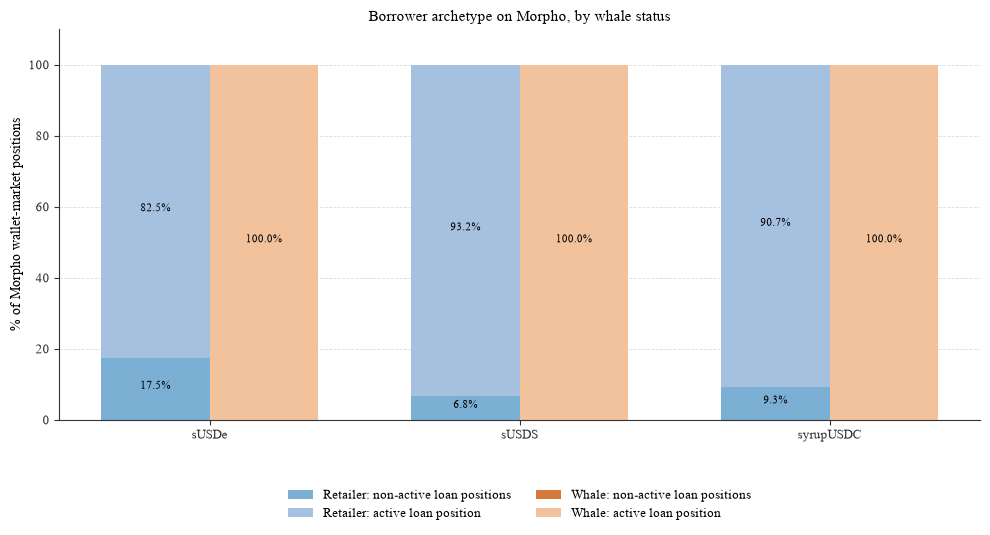

In [11]:
import numpy as np

morpho_whales = pd.read_csv("morpho_whales.csv")

def classify_morpho(row):
    return "collateral_only" if row["borrowed_value"] < 1 else "stablecoin_borrow"

def morpho_archetype_pct(df, token):
    df = df.copy()
    df["archetype"] = df.apply(classify_morpho, axis=1)

    whale_addresses = set(morpho_whales.loc[morpho_whales["asset"] == token, "wallet"])

    per_address = df.groupby("address").agg(
        is_whale=("address", lambda x: x.iloc[0] in whale_addresses),
        archetype=("archetype", lambda x: "stablecoin_borrow" if (x == "stablecoin_borrow").any() else "collateral_only"),
    ).reset_index()

    total_nonwhale = (~per_address["is_whale"]).sum()
    total_whale = per_address["is_whale"].sum()

    nonwhale_collateral = 100 * ((per_address["is_whale"] == False) & (per_address["archetype"] == "collateral_only")).sum() / total_nonwhale
    nonwhale_borrow = 100 * ((per_address["is_whale"] == False) & (per_address["archetype"] == "stablecoin_borrow")).sum() / total_nonwhale
    whale_collateral = 100 * ((per_address["is_whale"] == True) & (per_address["archetype"] == "collateral_only")).sum() / total_whale
    whale_borrow = 100 * ((per_address["is_whale"] == True) & (per_address["archetype"] == "stablecoin_borrow")).sum() / total_whale

    return nonwhale_collateral, nonwhale_borrow, whale_collateral, whale_borrow

tokens = list(morpho_dfs.keys())
data = {name: morpho_archetype_pct(morpho_dfs[name], name) for name in tokens}

x = np.arange(len(tokens))
w_bar = 0.35

nonwhale_collateral = [data[t][0] for t in tokens]
nonwhale_borrow = [data[t][1] for t in tokens]
whale_collateral = [data[t][2] for t in tokens]
whale_borrow = [data[t][3] for t in tokens]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.bar(x - w_bar/2, nonwhale_collateral, width=w_bar, color=RETAILER_COLOR, label="Retailer: non-active loan positions")
ax.bar(x - w_bar/2, nonwhale_borrow, width=w_bar, bottom=nonwhale_collateral, color=RETAILER_COLOR_LIGHT, label="Retailer: active loan position")

ax.bar(x + w_bar/2, whale_collateral, width=w_bar, color=WHALE_COLOR, label="Whale: non-active loan positions")
ax.bar(x + w_bar/2, whale_borrow, width=w_bar, bottom=whale_collateral, color=WHALE_COLOR_LIGHT, label="Whale: active loan position")

for i in range(len(tokens)):
    if nonwhale_collateral[i] > 3:
        ax.text(x[i] - w_bar/2, nonwhale_collateral[i]/2, f"{nonwhale_collateral[i]:.1f}%", ha="center", fontsize=8)
    ax.text(x[i] - w_bar/2, nonwhale_collateral[i] + nonwhale_borrow[i]/2, f"{nonwhale_borrow[i]:.1f}%", ha="center", fontsize=8)
    if whale_collateral[i] > 3:
        ax.text(x[i] + w_bar/2, whale_collateral[i]/2, f"{whale_collateral[i]:.1f}%", ha="center", fontsize=8)
    ax.text(x[i] + w_bar/2, whale_collateral[i] + whale_borrow[i]/2, f"{whale_borrow[i]:.1f}%", ha="center", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(tokens)
ax.set_ylabel("% of Morpho wallet-market positions")
ax.set_title("Borrower archetype on Morpho, by whale status")
ax.set_ylim(0, 110)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("../output/morpho_archetype_by_market_stacked.png", dpi=300, bbox_inches="tight")
plt.show()

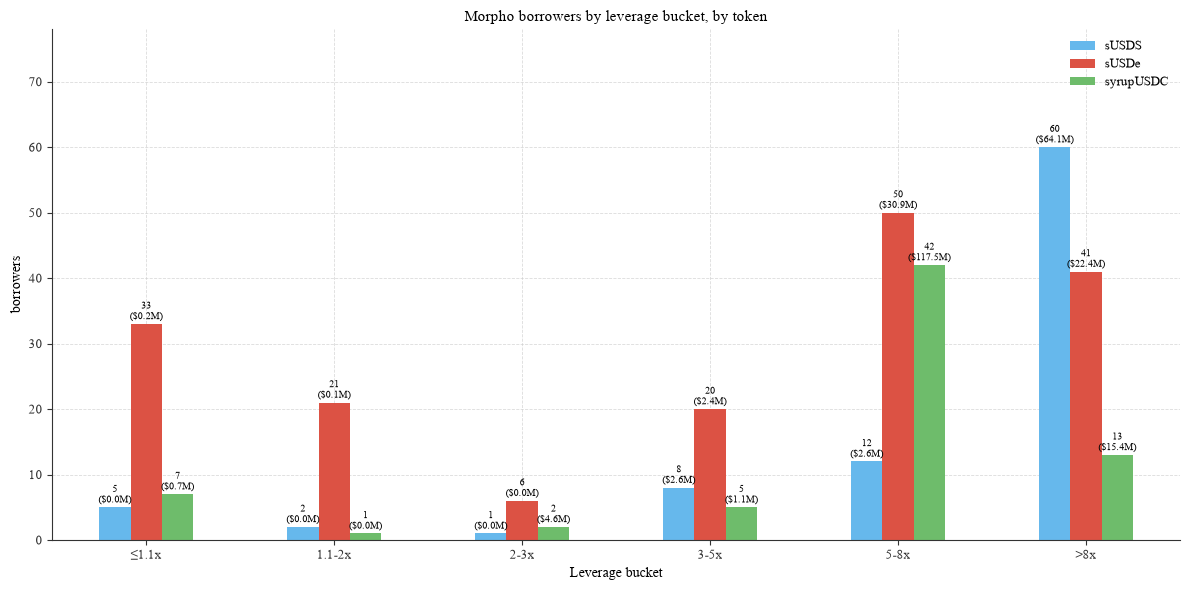

In [12]:
import numpy as np

LEVERAGE_BINS = [0, 1.1, 2, 3, 5, 8, np.inf]
LEVERAGE_LABELS = ["≤1.1x", "1.1-2x", "2-3x", "3-5x", "5-8x", ">8x"]

def leverage_bucket_summary(df, token):
    df = df.copy()
    df["leverage_bucket"] = pd.cut(df["leverage_market"], bins=LEVERAGE_BINS, labels=LEVERAGE_LABELS)

    per_address = df.groupby("address").agg(
        leverage_bucket=("leverage_bucket", "first"),
        collateral_value_usd=("collateral_value_usd", "sum"),
    ).reset_index()

    summary = (
        per_address.groupby("leverage_bucket", observed=True)
        .agg(borrowers=("address", "count"), total_collateral=("collateral_value_usd", "sum"))
        .reindex(LEVERAGE_LABELS)
        .fillna(0)
    )
    summary["token"] = token
    return summary.reset_index()

all_summaries = pd.concat([leverage_bucket_summary(df, name) for name, df in morpho_dfs.items()])

pivot_borrowers = all_summaries.pivot(index="leverage_bucket", columns="token", values="borrowers").reindex(LEVERAGE_LABELS)
pivot_collateral = all_summaries.pivot(index="leverage_bucket", columns="token", values="total_collateral").reindex(LEVERAGE_LABELS)

fig, ax = plt.subplots(figsize=(12, 6))
pivot_borrowers = pivot_borrowers[[c for c in TOKEN_COLORS if c in pivot_borrowers.columns]]
pivot_borrowers.plot(kind="bar", ax=ax, color=[TOKEN_COLORS[c] for c in pivot_borrowers.columns])

for container, token in zip(ax.containers, pivot_borrowers.columns):
    for bar, bucket in zip(container, pivot_borrowers.index):
        height = bar.get_height()
        collateral = pivot_collateral.loc[bucket, token]
        if height > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, height + 0.3,
                    f"{int(height)}\n(${collateral/1_000_000:.1f}M)",
                    ha="center", va="bottom", fontsize=7)

ax.set_title("Morpho borrowers by leverage bucket, by token")
ax.set_ylabel("borrowers")
ax.set_xlabel("Leverage bucket")
ax.set_ylim(0, pivot_borrowers.max().max() * 1.3)
plt.xticks(rotation=0)
ax.legend(title="")
plt.tight_layout()
plt.savefig("../output/leverage_bucket_combined.png", dpi=300, bbox_inches="tight")
plt.show()

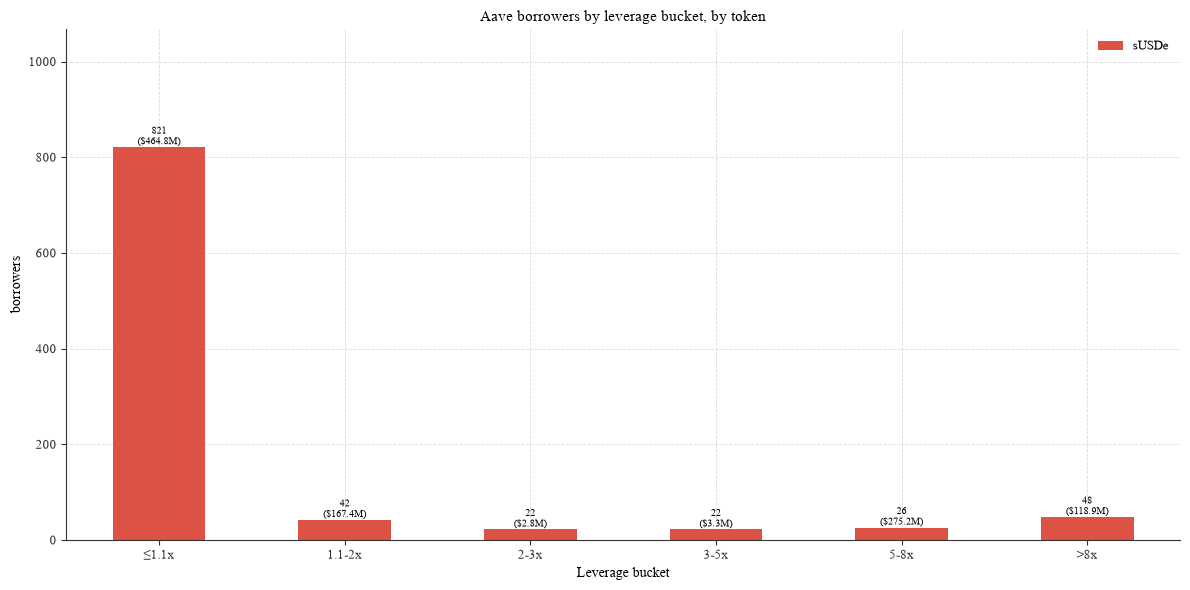

In [13]:
import numpy as np

STABLECOINS = {"USDT", "USDC", "USDe", "GHO", "EURC", "RLUSD", "USDtb", "PYUSD", "DAI", "USDS", "AUSD"}
LEVERAGE_BINS = [0, 1.1, 2, 3, 5, 8, np.inf]
LEVERAGE_LABELS = ["≤1.1x", "1.1-2x", "2-3x", "3-5x", "5-8x", ">8x"]

def aave_leverage_bucket_summary(df, token):
    df = df.copy()
    df["is_stable"] = df["debt_symbol"].isin(STABLECOINS)
    df["active_stable_borrow"] = df["borrowed_value"].where(df["is_stable"] & (df["borrowed_value"] > 0), 0)

    per_address = df.groupby("address").agg(
        total_borrowed=("active_stable_borrow", "sum"),
        collateral_value_usd=("collateral_value_usd", "first"),
    ).reset_index()

    ltv = per_address["total_borrowed"] / per_address["collateral_value_usd"]
    per_address["implied_leverage"] = (1 / (1 - ltv)).clip(upper=20)
    per_address["leverage_bucket"] = pd.cut(per_address["implied_leverage"], bins=LEVERAGE_BINS, labels=LEVERAGE_LABELS)

    summary = (
        per_address.groupby("leverage_bucket", observed=True)
        .agg(borrowers=("address", "count"), total_collateral=("collateral_value_usd", "sum"))
        .reindex(LEVERAGE_LABELS)
        .fillna(0)
    )
    summary["token"] = token
    return summary.reset_index()

aave_all_summaries = pd.concat([aave_leverage_bucket_summary(df, name) for name, df in aave_dfs.items()])

pivot_borrowers = aave_all_summaries.pivot(index="leverage_bucket", columns="token", values="borrowers").reindex(LEVERAGE_LABELS)
pivot_collateral = aave_all_summaries.pivot(index="leverage_bucket", columns="token", values="total_collateral").reindex(LEVERAGE_LABELS)

fig, ax = plt.subplots(figsize=(12, 6))
pivot_borrowers = pivot_borrowers[[c for c in TOKEN_COLORS if c in pivot_borrowers.columns]]
pivot_borrowers.plot(kind="bar", ax=ax, color=[TOKEN_COLORS[c] for c in pivot_borrowers.columns])

for container, token in zip(ax.containers, pivot_borrowers.columns):
    for bar, bucket in zip(container, pivot_borrowers.index):
        height = bar.get_height()
        collateral = pivot_collateral.loc[bucket, token]
        if height > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, height + 0.3,
                    f"{int(height)}\n(${collateral/1_000_000:.1f}M)",
                    ha="center", va="bottom", fontsize=7)

ax.set_title("Aave borrowers by leverage bucket, by token")
ax.set_ylabel("borrowers")
ax.set_xlabel("Leverage bucket")
ax.set_ylim(0, pivot_borrowers.max().max() * 1.3)
plt.xticks(rotation=0)
ax.legend(title="")
plt.tight_layout()
plt.savefig("../output/aave_leverage_bucket_combined.png", dpi=300, bbox_inches="tight")
plt.show()